In [35]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 

In [36]:
df = pd.read_csv('telegram_messages.csv')
df.head()

,chat_id,message_id,sender_id,text,sent_at,reply_to_msg_id,edited_at,collected_at
0,-1002228561044,12,5244660552,"Саламатсыз Ба, Рупты Жибересиз Ба? \nИнформаци...",2024-08-23 14:48:00+00,NaN,NaN,2026-11-10 11:01:39.32213+00
1,-1002228561044,14,408834217,2022-2023 это,2024-08-23 14:48:49+00,NaN,NaN,2026-11-10 11:01:39.32213+00
2,-1002228561044,16,483301967,После зачисления отправят,2024-08-23 15:18:16+00,12.0,NaN,2026-11-10 11:01:39.32213+00
3,-1002228561044,17,5244660552,👍,2024-08-23 15:44:31+00,NaN,NaN,2026-11-10 11:01:39.32213+00
4,-1002228561044,19,5244660552,Ты имеешт ввиду в всп зачисление?,2024-08-23 16:05:38+00,16.0,NaN,2026-11-10 11:01:39.32213+00


In [37]:
df['sent_at'] = pd.to_datetime(df['sent_at'])
df['sent_at'] = df['sent_at'].dt.tz_convert('Asia/Almaty')

In [38]:
df.head()

,chat_id,message_id,sender_id,text,sent_at,reply_to_msg_id,edited_at,collected_at
0,-1002228561044,12,5244660552,"Саламатсыз Ба, Рупты Жибересиз Ба? \nИнформаци...",2024-08-23 19:48:00+05:00,NaN,NaN,2026-11-10 11:01:39.32213+00
1,-1002228561044,14,408834217,2022-2023 это,2024-08-23 19:48:49+05:00,NaN,NaN,2026-11-10 11:01:39.32213+00
2,-1002228561044,16,483301967,После зачисления отправят,2024-08-23 20:18:16+05:00,12.0,NaN,2026-11-10 11:01:39.32213+00
3,-1002228561044,17,5244660552,👍,2024-08-23 20:44:31+05:00,NaN,NaN,2026-11-10 11:01:39.32213+00
4,-1002228561044,19,5244660552,Ты имеешт ввиду в всп зачисление?,2024-08-23 21:05:38+05:00,16.0,NaN,2026-11-10 11:01:39.32213+00


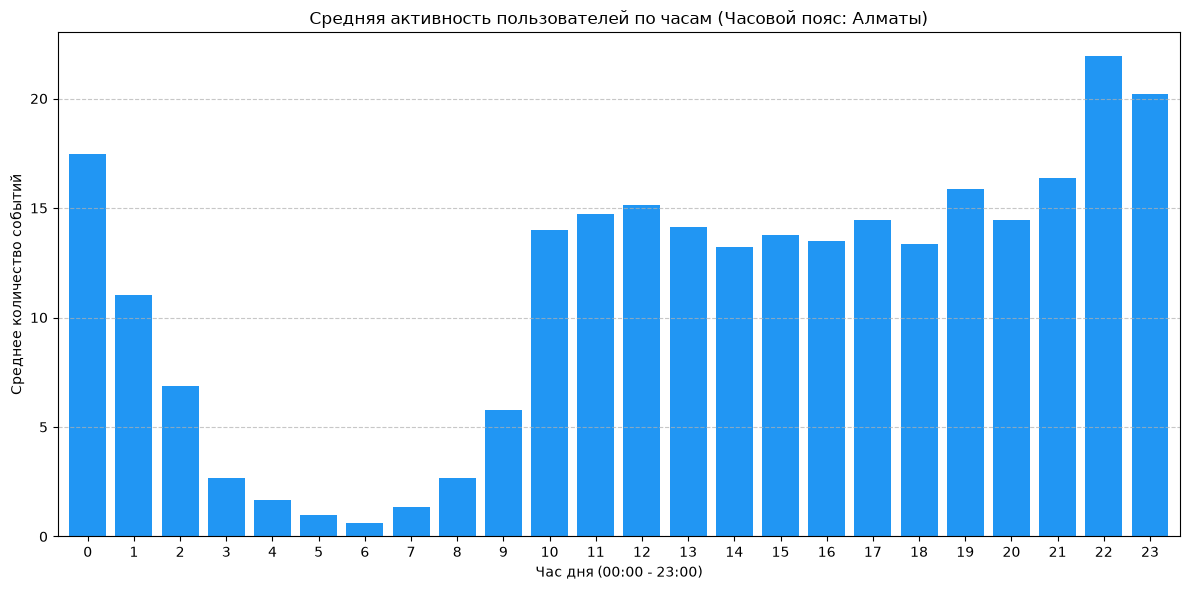

In [39]:
# 2. Извлекаем дату и час в отдельные колонки
df['date'] = df['sent_at'].dt.date
df['hour'] = df['sent_at'].dt.hour

# 3. Считаем количество записей для каждого часа в каждый конкретный день.
# unstack(fill_value=0) делает даты строками, а часы (0-23) — столбцами, заполняя пустоты нулями.
daily_hourly_counts = df.groupby(['date', 'hour']).size().unstack(fill_value=0)

# 4. Считаем среднее арифметическое по каждому часу за весь период
average_hourly_activity = daily_hourly_counts.mean()

# 5. Строим график
average_hourly_activity.plot(kind='bar', figsize=(12, 6), color='#2196F3', width=0.8)

plt.title('Средняя активность пользователей по часам (Часовой пояс: Алматы)')
plt.xlabel('Час дня (00:00 - 23:00)')
plt.ylabel('Среднее количество событий')
plt.xticks(range(0, 24), rotation=0) # Принудительно показываем все 24 часа
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

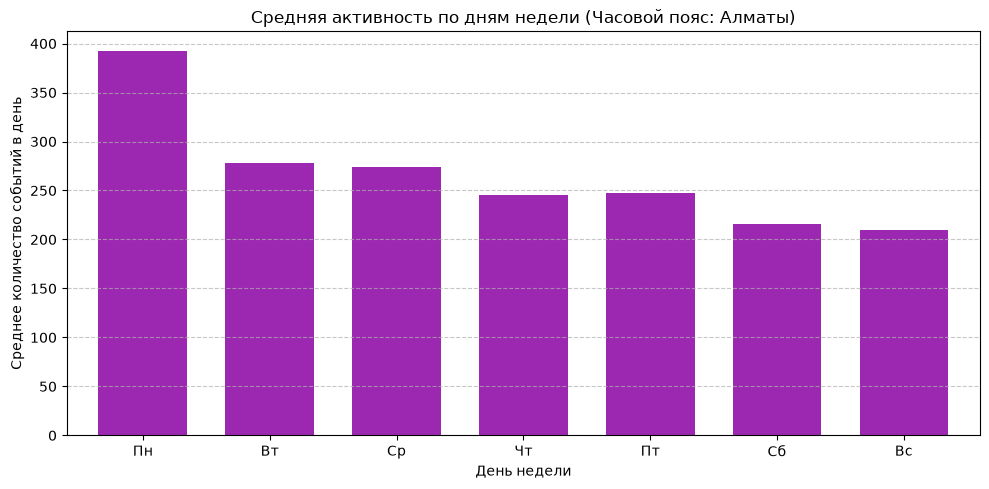

In [40]:
# 1. Делаем колонку со временем индексом таблицы (это необходимо для resample)
df_indexed = df.set_index('sent_at')

# 2. Считаем количество записей за каждый календарный день за весь период.
# 'D' означает ежедневную частоту. Дни без записей получат значение 0.
daily_counts = df_indexed.resample('D').size().reset_index(name='count')

# 3. Извлекаем номер дня недели (0 - Понедельник, 1 - Вторник, ..., 6 - Воскресенье)
daily_counts['weekday'] = daily_counts['sent_at'].dt.dayofweek

# 4. Считаем среднее количество событий для каждого дня недели
average_weekday_activity = daily_counts.groupby('weekday')['count'].mean()

# 5. Переименовываем числовые индексы (0-6) в читаемые названия дней
days_ru = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
average_weekday_activity.index = days_ru

# 6. Строим график
average_weekday_activity.plot(kind='bar', figsize=(10, 5), color='#9C27B0', width=0.7)

plt.title('Средняя активность по дням недели (Часовой пояс: Алматы)')
plt.xlabel('День недели')
plt.ylabel('Среднее количество событий в день')
plt.xticks(rotation=0) # Оставляем подписи горизонтальными
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

     sender_id  message_count
0    890034313          10054
1   1799470808           7537
2   1281670164           7165
3    644190224           4992
4   6279046710           3843
5   1204458788           3738
6   1274574894           3472
7    727569500           3409
8    757351060           3390
9   1013474971           3181
10  1394886797           3097
11  1510317773           3012
12  5075118352           2980
13  6376217793           2941
14  1169430094           2859
15  6533593445           2645
16  1256556556           2550
17   901371576           2534
18   964528847           2182
19  1116539677           1948
20  1666048735           1802
21  1831169176           1748
22   818386205           1612
23   927900274           1421
24  6629842245           1410
25  6546994550           1405
26   236577806           1371
27   746714695           1358
28   679192465           1354
29  7117537800           1337
30  7552518556           1289
31  1064307167           1246
32  147599

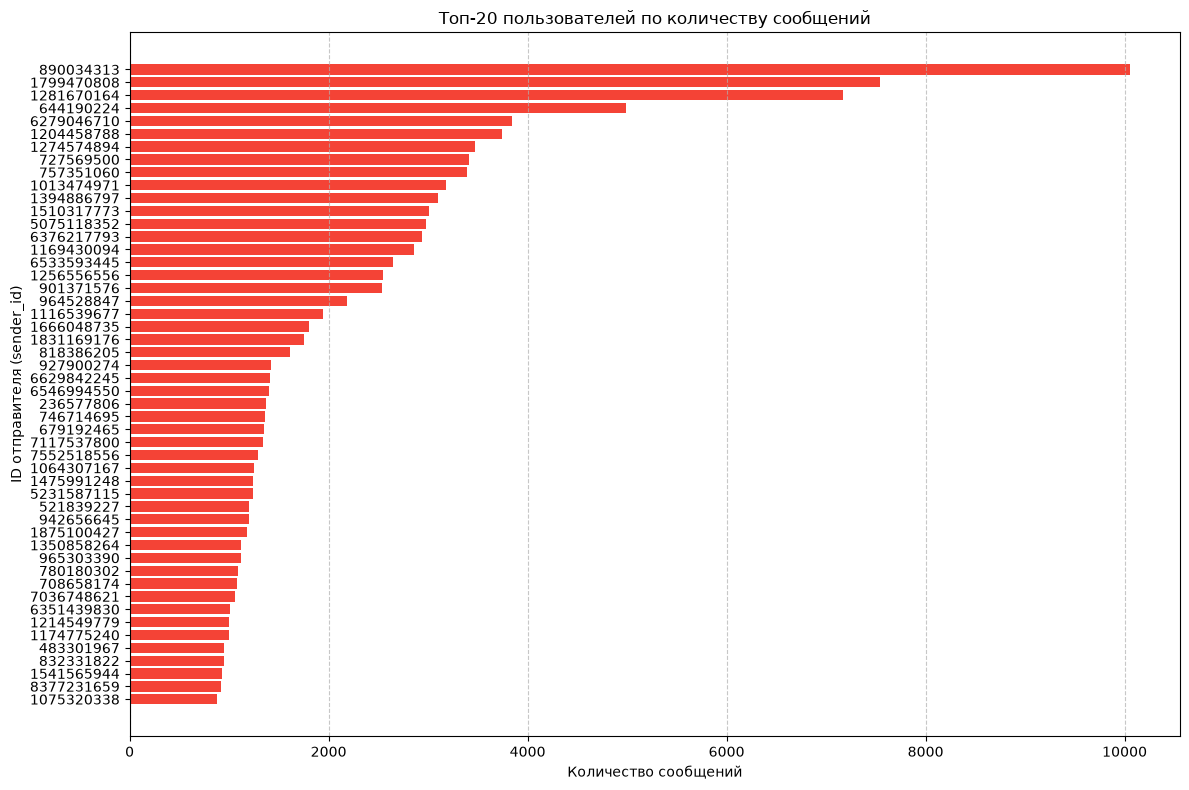

In [53]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Считаем количество сообщений для каждого sender_id и берем топ-20
top_20_senders = df['sender_id'].value_counts().head(50).reset_index()

# 2. Переименовываем колонки для удобства
top_20_senders.columns = ['sender_id', 'message_count']

# Выводим таблицу в консоль
print(top_20_senders)

# 3. Строим график
plt.figure(figsize=(12, 8))
# Переводим sender_id в строку, чтобы на оси Y они отображались как категории, а не числа
plt.barh(top_20_senders['sender_id'].astype(str), top_20_senders['message_count'], color='#F44336')

plt.gca().invert_yaxis() # Переворачиваем ось Y, чтобы лидер (топ-1) был на самом верху
plt.title('Топ-20 пользователей по количеству сообщений')
plt.xlabel('Количество сообщений')
plt.ylabel('ID отправителя (sender_id)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [42]:
# Фильтруем по ID, сортируем по времени по убыванию и берем 1 самую свежую запись
df[df['sender_id'] == 890034313].sort_values(by='sent_at', ascending=False).head(20)

,chat_id,message_id,sender_id,text,sent_at,reply_to_msg_id,edited_at,collected_at,date,hour
215518,-1002228561044,235207,890034313,/nuriddin_stipa_qaida,2026-11-10 11:58:12+05:00,NaN,NaN,2026-11-10 12:05:35.723684+00,2026-11-10,11
215460,-1002228561044,235147,890034313,11,2026-11-09 23:52:38+05:00,NaN,NaN,2026-11-10 12:05:35.723684+00,2026-11-09,23
215306,-1002228561044,234859,890034313,v dekabre tok,2026-11-09 09:40:38+05:00,NaN,2026-11-09 04:46:56+00,2026-11-10 12:05:35.723684+00,2026-11-09,9
215305,-1002228561044,234858,890034313,rano eshe,2026-11-09 09:40:30+05:00,NaN,NaN,2026-11-10 12:05:35.723684+00,2026-11-09,9
214685,-1002228561044,234220,890034313,вот сюда я пойду,2026-11-04 17:02:50+05:00,234217.0,2026-11-04 12:03:32+00,2026-11-10 12:05:35.723684+00,2026-11-04,17
214635,-1002228561044,234169,890034313,/vtipo_sila,2026-11-03 23:02:31+05:00,NaN,NaN,2026-11-10 12:05:35.723684+00,2026-11-03,23
214587,-1002228561044,234121,890034313,NaN,2026-11-03 19:55:22+05:00,234114.0,2026-11-03 17:09:01+00,2026-11-10 12:05:35.723684+00,2026-11-03,19
214581,-1002228561044,234113,890034313,/vtipo_sila,2026-11-03 19:02:42+05:00,NaN,2026-11-03 14:02:50+00,2026-11-10 12:05:35.723684+00,2026-11-03,19
214568,-1002228561044,234100,890034313,пф3,2026-11-03 16:42:48+05:00,234098.0,NaN,2026-11-10 12:05:35.723684+00,2026-11-03,16
214508,-1002228561044,234038,890034313,аа,2026-11-02 23:10:46+05:00,NaN,NaN,2026-11-10 12:05:35.723684+00,2026-11-02,23


In [43]:
# 2. Фильтруем по конкретной дате (7 июля 2026) и времени (22:24)
target_date = pd.to_datetime('2026-07-07').date()

result_df = df[
    (df['sent_at'].dt.date == target_date) & 
    (df['sent_at'].dt.hour == 22) & 
    (df['sent_at'].dt.minute == 24)
]

# 3. Выводим результат
result_df

,chat_id,message_id,sender_id,text,sent_at,reply_to_msg_id,edited_at,collected_at,date,hour
191419,-1002228561044,209617,5075118352,"Шанс ппц мал, что отыграются. Но надо верить",2026-07-07 22:24:03+05:00,NaN,2026-07-07 17:24:20+00,2026-11-10 12:05:35.723684+00,2026-07-07,22
191420,-1002228561044,209618,1184657161,Отменят,2026-07-07 22:24:22+05:00,NaN,NaN,2026-11-10 12:05:35.723684+00,2026-07-07,22
191421,-1002228561044,209619,1194641284,Гг,2026-07-07 22:24:26+05:00,NaN,NaN,2026-11-10 12:05:35.723684+00,2026-07-07,22
191422,-1002228561044,209620,1380727989,не гг,2026-07-07 22:24:29+05:00,NaN,NaN,2026-11-10 12:05:35.723684+00,2026-07-07,22
191423,-1002228561044,209621,5075118352,Повезло,2026-07-07 22:24:36+05:00,NaN,NaN,2026-11-10 12:05:35.723684+00,2026-07-07,22
191424,-1002228561044,209622,1831169176,купили,2026-07-07 22:24:42+05:00,NaN,NaN,2026-11-10 12:05:35.723684+00,2026-07-07,22
191425,-1002228561044,209623,5075118352,Маловероятно,2026-07-07 22:24:59+05:00,209622.0,NaN,2026-11-10 12:05:35.723684+00,2026-07-07,22


In [44]:
df[df['sender_id'] == 1194641284].sort_values(by='sent_at').head(20)

,chat_id,message_id,sender_id,text,sent_at,reply_to_msg_id,edited_at,collected_at,date,hour
57301,-1002228561044,65666,1194641284,Койсай Адилет,2025-03-03 10:49:30+05:00,65660.0,NaN,2026-11-10 11:40:02.108959+00,2025-03-03,10
57311,-1002228561044,65676,1194641284,Старшактар,2025-03-03 10:50:04+05:00,65671.0,NaN,2026-11-10 11:40:02.108959+00,2025-03-03,10
57318,-1002228561044,65684,1194641284,Скамшик десе,2025-03-03 10:50:50+05:00,65671.0,NaN,2026-11-10 11:40:02.108959+00,2025-03-03,10
57333,-1002228561044,65701,1194641284,Койсай,2025-03-03 10:53:29+05:00,65696.0,NaN,2026-11-10 11:40:02.108959+00,2025-03-03,10
58346,-1002228561044,66757,1194641284,Жиги ким ауысады:\nМашин лернингты \nНа \nИнтр...,2025-03-03 19:58:35+05:00,NaN,NaN,2026-11-10 11:40:02.108959+00,2025-03-03,19
58347,-1002228561044,66758,1194641284,Причина: я не гений\nЯ жб завалить етем ананы,2025-03-03 19:59:08+05:00,66757.0,2025-03-03 14:59:19+00,2026-11-10 11:40:02.108959+00,2025-03-03,19
58350,-1002228561044,66761,1194641284,Кредит осип кетти,2025-03-03 20:00:20+05:00,66756.0,NaN,2026-11-10 11:40:02.108959+00,2025-03-03,20
58352,-1002228561044,66763,1194641284,"Брат зачем интро2мл,млнын ози турганда",2025-03-03 20:00:51+05:00,66760.0,2025-03-03 15:01:02+00,2026-11-10 11:40:02.108959+00,2025-03-03,20
58356,-1002228561044,66767,1194641284,"Да в августе можно, add drop week",2025-03-03 20:02:09+05:00,66766.0,2025-03-03 15:02:22+00,2026-11-10 11:40:02.108959+00,2025-03-03,20
58359,-1002228561044,66770,1194641284,Фух блэ я не один лох,2025-03-03 20:04:08+05:00,66717.0,NaN,2026-11-10 11:40:02.108959+00,2025-03-03,20


In [47]:
import pandas as pd
from collections import Counter
import re

# 1. Объединяем все сообщения в одну большую строку (предварительно удалив пустые/пропущенные значения)
text_data = df['text'].dropna().astype(str).str.lower()

# 2. Разбиваем текст на отдельные слова с помощью регулярного выражения (убираем знаки препинания)
# \w+ находит все слова (можно заменить на \b\w{3,}\b, если хотите искать только слова длиннее 3 букв)
all_words = []
for text in text_data:
    words = re.findall(r'\b\w+\b', text)
    all_words.extend(words)

# 3. Считаем частоту каждого слова и выводим ТОП-20
word_counts = Counter(all_words)
top_20 = word_counts.most_common(20)

print("Топ-20 самых частых слов:")
for word, freq in top_20:
    print(f"{word}: {freq} раз(а)")

Топ-20 самых частых слов:
не: 23220 раз(а)
в: 22075 раз(а)
и: 16505 раз(а)
на: 15776 раз(а)
я: 12232 раз(а)
у: 11242 раз(а)
а: 10713 раз(а)
что: 10114 раз(а)
по: 8731 раз(а)
да: 8694 раз(а)
это: 7964 раз(а)
с: 7520 раз(а)
как: 7363 раз(а)
то: 7189 раз(а)
если: 6750 раз(а)
есть: 5835 раз(а)
там: 5535 раз(а)
так: 5342 раз(а)
все: 5263 раз(а)
же: 5076 раз(а)


In [48]:
import pandas as pd
from collections import Counter
import re

# 1. Собираем все слова из столбца message в нижнем регистре
text_data = df['text'].dropna().astype(str).str.lower()

all_words = []
for text in text_data:
    # Находим все слова (буквенно-цифровые последовательности)
    words = re.findall(r'\b\w+\b', text)
    all_words.extend(words)

# 2. Оставляем только те слова, длина которых СТРОГО больше 4 символов (len > 4)
long_words = [word for word in all_words if len(word) > 4]

# 3. Считаем частоту и выводим ТОП-20
word_counts = Counter(long_words)
top_20_long = word_counts.most_common(20)

print("Топ-20 самых частых слов (длиной > 4 символов):")
for word, freq in top_20_long:
    print(f"{word}: {freq} раз(а)")

Топ-20 самых частых слов (длиной > 4 символов):
можно: 4112 раз(а)
будет: 4085 раз(а)
просто: 3496 раз(а)
только: 2730 раз(а)
когда: 2514 раз(а)
вроде: 2217 раз(а)
спасибо: 1735 раз(а)
нужно: 1516 раз(а)
лучше: 1469 раз(а)
nuriddin_gde_stipuha: 1455 раз(а)
вообще: 1413 раз(а)
потом: 1334 раз(а)
чтобы: 1261 раз(а)
почему: 1257 раз(а)
тогда: 1250 раз(а)
время: 1243 раз(а)
через: 1174 раз(а)
может: 1173 раз(а)
https: 1157 раз(а)
какой: 1152 раз(а)


In [ ]:
import pandas as pd

# 1. Убедимся, что столбец sent_at имеет формат datetime
df['sent_at'] = pd.to_datetime(df['sent_at'])

# 2. Извлекаем номер месяца и год (чтобы корректно посчитать среднее)
df['year'] = df['sent_at'].dt.year
df['month'] = df['sent_at'].dt.month

# 3. Считаем количество сообщений для каждого конкретного месяца и года
monthly_counts = df.groupby(['year', 'month']).size().reset_index(name='count')

# 4. Находим СРЕДНЕЕ количество сообщений по каждому месяцу (например, сколько в среднем сообщений было в январе, феврале и т.д. за все годы)
avg_activity_by_month = monthly_counts.groupby('month')['count'].mean().reset_index()

# Красивые названия месяцев для наглядности
month_names = {
    1: 'Январь', 2: 'Февраль', 3: 'Март', 4: 'Апрель', 
    5: 'Май', 6: 'Июнь', 7: 'Июль', 8: 'Август', 
    9: 'Сентябрь', 10: 'Октябрь', 11: 'Ноябрь', 12: 'Декабрь'
}
avg_activity_by_month['month_name'] = avg_activity_by_month['month'].map(month_names)

# Переупорядочим для удобства
avg_activity_by_month = avg_activity_by_month[['month_name', 'count']].rename(columns={'count': 'avg_messages'})

print("Средняя активность сообщений по месяцам:")
print(avg_activity_by_month)

import pandas as pd

# 1. Приводим столбец к datetime и группируем по месяцам
df['sent_at'] = pd.to_datetime(df['sent_at'])
monthly_counts = df.groupby(df['sent_at'].dt.to_period('M')).size()

# 2. Строим график прямо в Jupyter / Python
monthly_counts.plot(kind='line', marker='o', figsize=(10, 5), grid=True, title='Активность по месяцам')

Активность по дням месяца:
day_of_month
1      8260
2      9471
3      8030
4      8137
5     10119
6     11724
7      6090
8      6532
9      4764
10     5926
11     6071
12     6632
13     4808
14     5851
15     5367
16     7054
17     6646
18     5630
19     7264
20     8323
21     5197
22     5303
23     6099
24     5150
25     6402
26     5448
27     8692
28    12532
29     6366
30     6678
31     5036
Name: count, dtype: int64


<Axes: title={'center': 'Активность по дням месяца (1-31)'}, xlabel='day_of_month'>

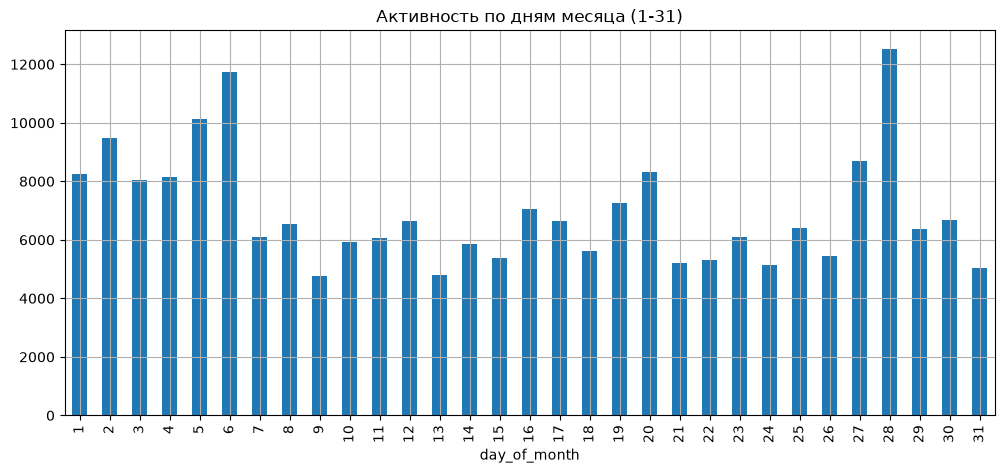

In [52]:
import pandas as pd

# 1. Проверяем формат datetime
df['sent_at'] = pd.to_datetime(df['sent_at'])

# 2. Извлекаем день месяца (от 1 до 31)
df['day_of_month'] = df['sent_at'].dt.day

# 3. Считаем суммарное количество сообщений для каждого дня месяца
activity_by_day = df['day_of_month'].value_counts().sort_index()

print("Активность по дням месяца:")
print(activity_by_day)

# (Опционально) Построение графика прямо в Python
activity_by_day.plot(kind='bar', figsize=(12, 5), title='Активность по дням месяца (1-31)', grid=True)

In [56]:
import pandas as pd

# 1. Ищем строки, где в столбце 'message' содержится нужная фраза 
# (используем .str.contains без учета регистра и пробелов по краям, если нужно)
target_phrase = "а на шахматы"
found_rows = df[df['text'].astype(str).str.lower().str.contains(target_phrase, na=False)]

# 2. Выводим найденные строки
found_rows.head()

,chat_id,message_id,sender_id,text,sent_at,reply_to_msg_id,edited_at,collected_at,date,hour,year,month,day_of_month
137088,-1002228561044,150783,1833004619,а на шахматы есть варик поменять ?,2026-01-04 23:54:11+05:00,150776.0,2026-01-04 18:54:56+00,2026-11-10 11:55:27.095667+00,2026-01-04,23,2026,1,4


In [57]:
1833004619

1833004619

In [60]:
import pandas as pd

# 1. Фильтруем данные и сортируем по времени отправки
filtered_df = df[df['sender_id'] == 1833004619].sort_values(by='sent_at')

# 2. Сохраняем в CSV-файл (encoding='utf-8-sig' обязателен для корректного отображения кириллицы)
file_name = 'sender_1833004619_messages.csv'
filtered_df.to_csv(file_name, index=False, encoding='utf-8-sig')

print(f"Файл успешно сохранен как: {file_name}")

Файл успешно сохранен как: sender_1833004619_messages.csv
